# 01 · Búsqueda causal en todo el genoma codificante

> **Lugar en el argumento:** Track 1, descubrimiento. Comprueba si la hipótesis `BUB1B`
> sobrevive cuando compite contra todos los genes y no contra un panel elegido a mano.
>
> **Salida principal:** ranking genome-wide, estabilidad frente a perturbaciones y comparación
> metodológica con Exomiser. No clasifica variantes ni demuestra causalidad.

> **Reproduce el experimento desde las entradas.** No muestra resultados guardados: reejecuta
> el pipeline importando `src/`, que es la fuente de verdad.
>
> **Saneado:** agregados, conteos y símbolos de gen. Nunca coordenadas, genotipos ni identidad
> de variantes. El propio notebook corre el escáner al final.

## Pregunta biológica

**¿Qué gen explica mejor el caso cuando compite todo el genoma codificante?**

Hasta EXP-006, `BUB1B` aparecía fuerte **dentro de un panel que elegimos nosotros**. Eso no es
lo mismo que sobrevivir a una búsqueda sin panel.

## Hipótesis y preregistro

`docs/DECISIONS.md` § EXP-006, escrito antes de ejecutar. La predicción que importa es la #4:
**`BUB1B` queda entre los 20 primeros** del ranking sin panel. Los dos desenlaces se
declararon buenos por adelantado: si no quedaba arriba, habríamos evitado un error.

**Garantía de diseño:** `src/prioritization/extract_genomewide.py` no menciona ningún gen.

### Integración visual · 24 septiembre 2026

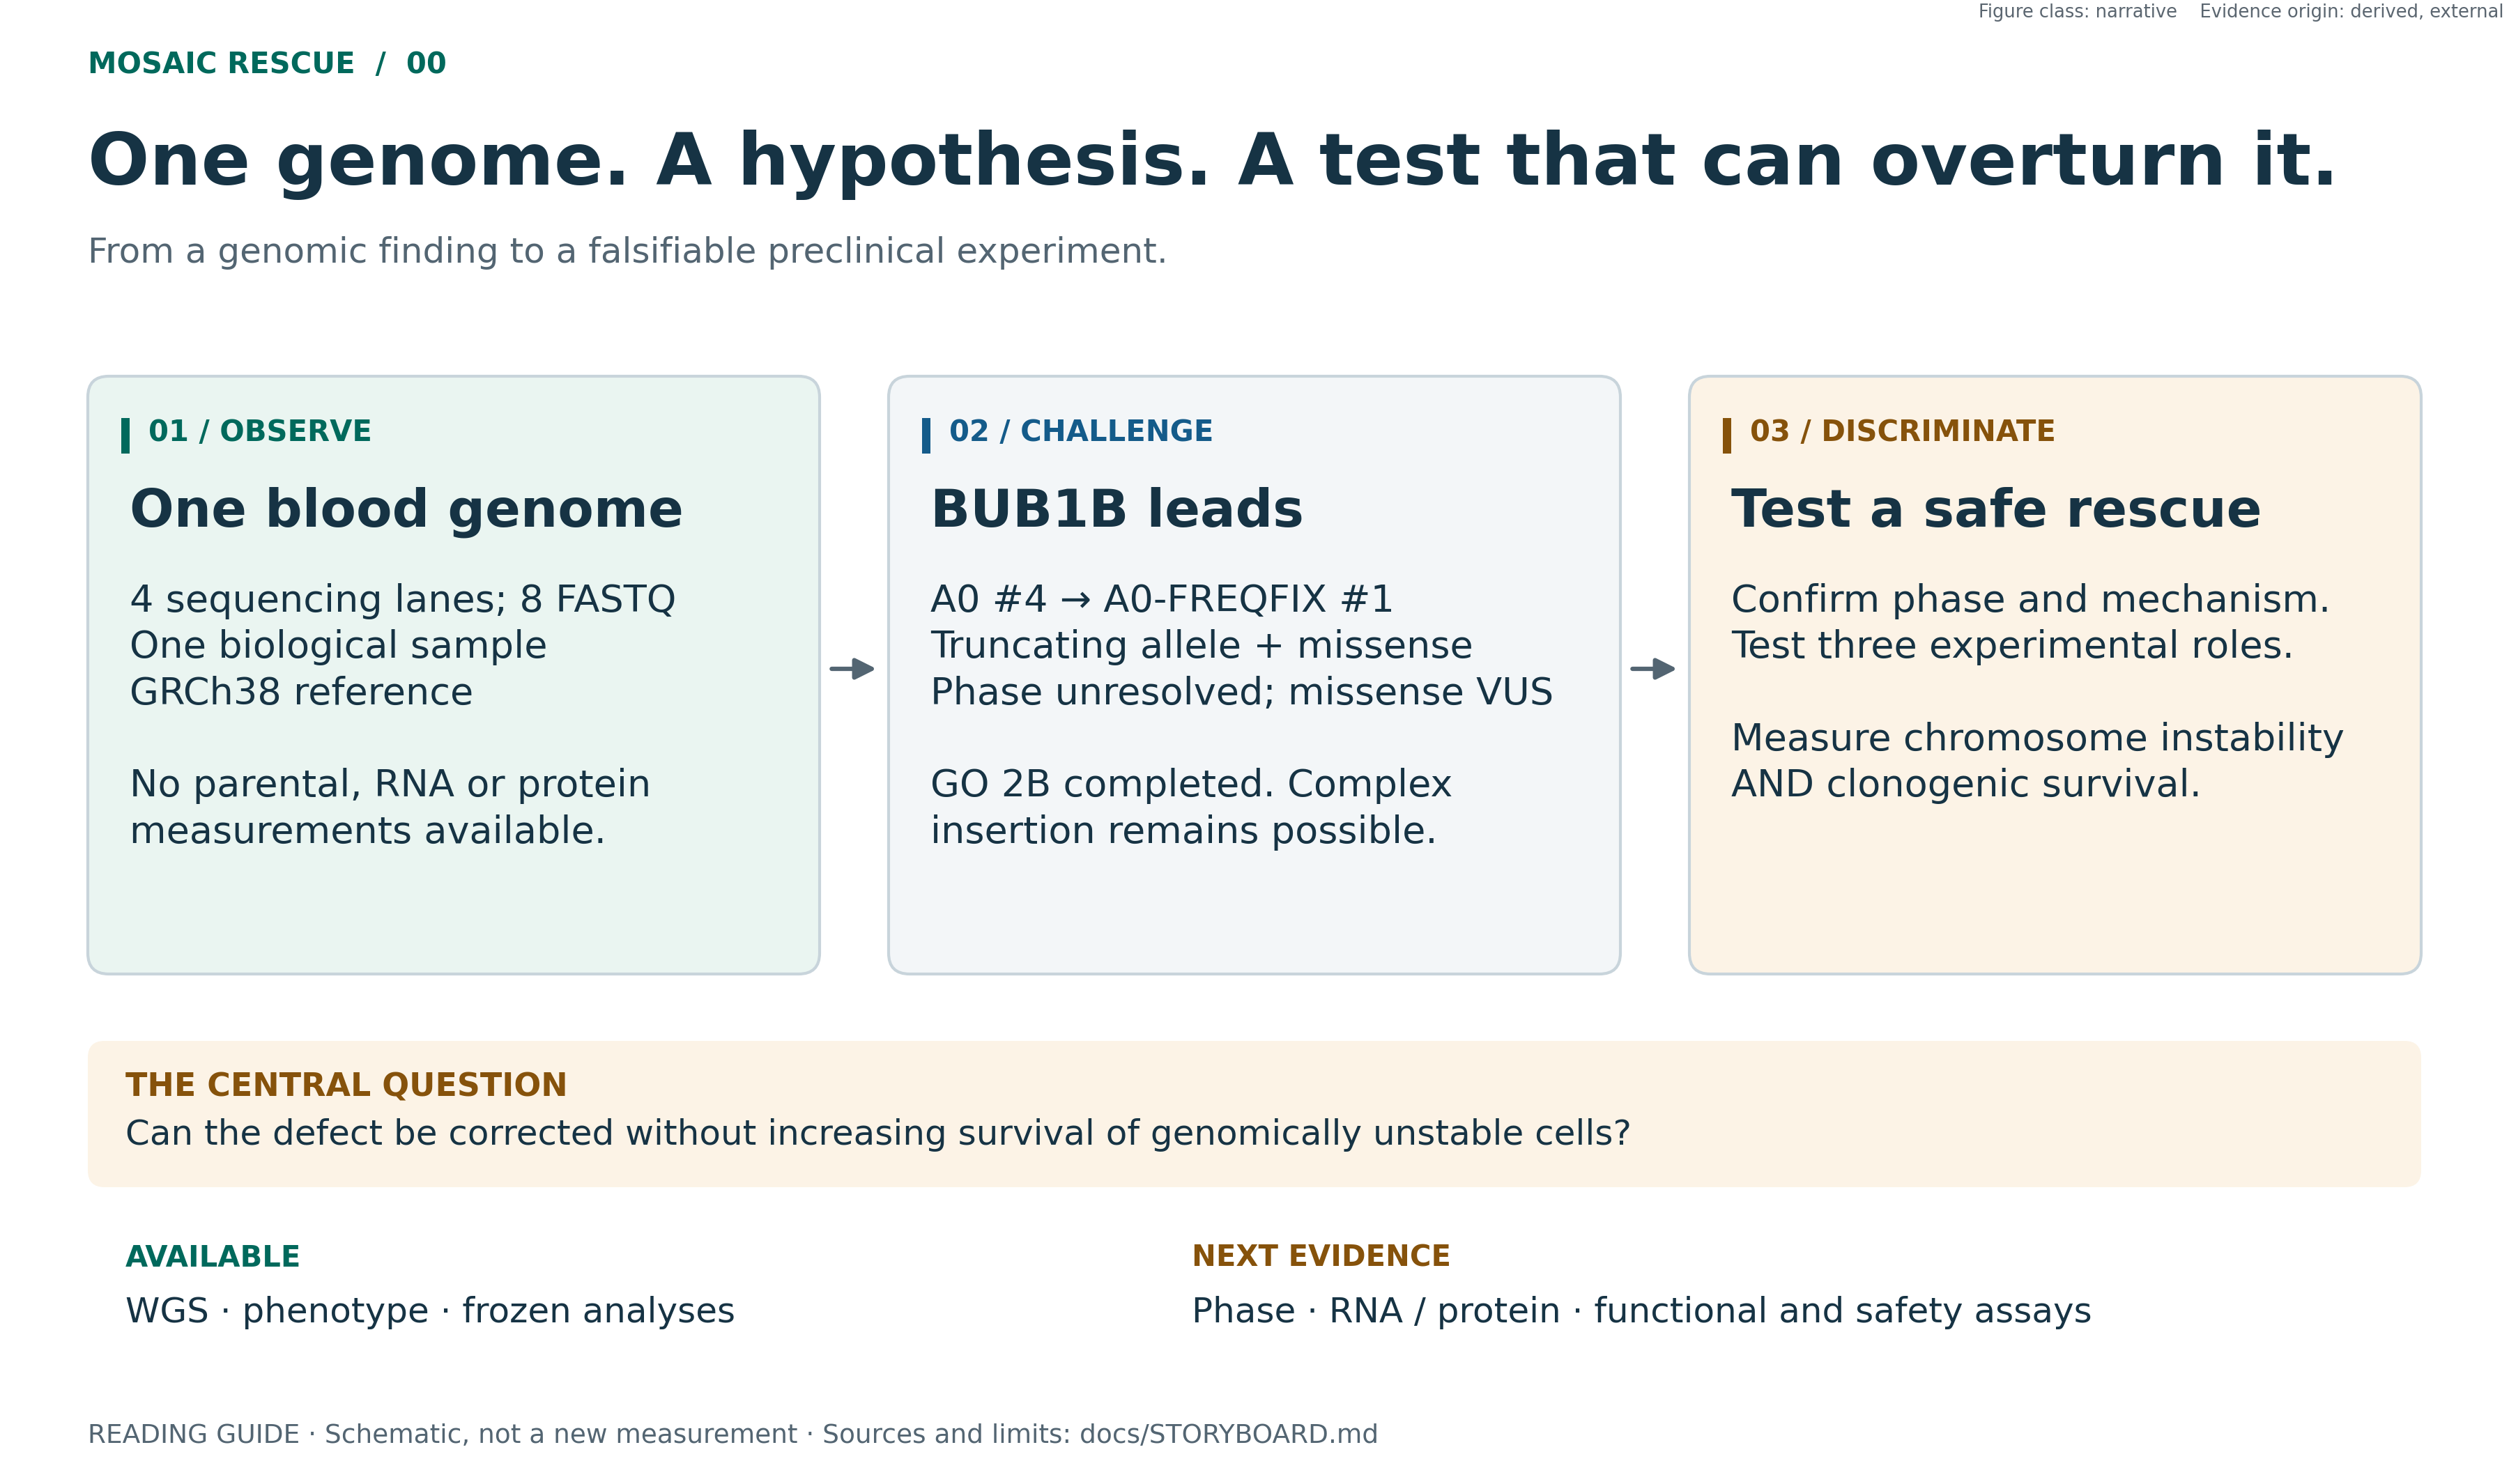

**NARRATIVE · DERIVED / EXTERNAL.** El ranking A0 congelado y su revisión A0-FREQFIX son etapas distintas. La convergencia de herramientas sobre el mismo VCF no es replicación biológica.

Figura importada del artefacto revisado, sin reejecutar el análisis original. [Fuentes y límites](../docs/STORYBOARD.md) · [QA](../PUBLICATION_FIGURE_QA.md).

In [1]:
import sys, os, io, json, pickle, collections
os.chdir("..")                       # el pipeline usa rutas relativas a la raiz
sys.path.insert(0, ".")
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from src.nb import figlib as fl      # figuras inline + caption con procedencia
print("entorno listo · las figuras de este notebook aparecen INLINE, con caption")

entorno listo · las figuras de este notebook aparecen INLINE, con caption


In [2]:
fl.labels("Que muestra", "Lo que queda fuera")

## Entradas y procedencia

Se verifican los hashes. La anotación con VEP 116.1 offline (caché de 27 GB, horas de cómputo)
es un paso aguas arriba **no reejecutable aquí**: el notebook parte de su salida y comprueba
su huella.

In [3]:
import hashlib
from src.paths import patient_vcf

def h(p, n=64 << 20):
    return hashlib.sha256(io.open(p, "rb").read(n)).hexdigest()[:16]

VCF, ANN = patient_vcf(), "work/gw/highmod_ann.tsv"
print(f"  VCF del paciente   sha256[:16] = {h(VCF)}   ({os.path.getsize(VCF)/2**20:.0f} MB)")
print(f"  TSV anotado (VEP)  sha256[:16] = {h(ANN)}   ({os.path.getsize(ANN)/2**20:.0f} MB)")
print(f"  python {sys.version.split()[0]}  ·  no se imprime ninguna ruta local")

  VCF del paciente   sha256[:16] = 645e4693e399b395   (301 MB)
  TSV anotado (VEP)  sha256[:16] = 6bb5d13907efa9d5   (6 MB)
  python 3.12.5  ·  no se imprime ninguna ruta local


## QC · reconciliación exacta de alelos VEP ↔ VCF

**El error que este notebook destapó.** `allele_key.py` existía, tenía 17 tests que pasaban y
estaba documentado como la corrección del cruce. **Ningún módulo lo importaba**: `load()`
cruzaba por posición, justo lo que ese módulo venía a arreglar.

VEP desplaza la coordenada de los indels respecto al VCF, así que un cruce por posición los
pierde. La solución **no pudo ser** `Uploaded_variation` (este TSV no la tiene) sino reproducir
las reglas de representación de VEP y cruzar por `(Location, Allele)`. Sin tolerancias: la
proximidad no es una clave de unión, y ese arreglo ya se había rechazado antes por poder
emparejar indels vecinos distintos.

In [4]:
os.environ["PYTEST_DISABLE_PLUGIN_AUTOLOAD"] = "1"
import subprocess
r = subprocess.run([sys.executable, "-m", "pytest", "tests/test_allele_key.py", "-q"],
                   capture_output=True, text=True)
print("  tests del join:", r.stdout.strip().splitlines()[-1] if r.stdout.strip() else "sin salida")
assert r.returncode == 0, "los tests del join fallan: nada de abajo es fiable"

  tests del join: 17 passed in 0.04s


In [5]:
import gzip
from src.prioritization.genome_wide import load, rank, haplotypic_events

rows = load(ANN, VCF)                      # cruce ACTUAL: (Location, Allele)
hm = [v for v in rows if v.impact in ("HIGH", "MODERATE")]

# Cruce ANTIGUO, reconstruido aqui para medir el tamano del bug: solo posicion.
want = {v.loc.split(":")[0] + ":" + v.loc.split(":")[1].split("-")[0] for v in rows}
seen_pos = set()
with gzip.open(VCF, "rt", errors="replace") as f:
    for line in f:
        if line[0] == "#":
            continue
        p = line.split("\t", 2)
        k = f"{p[0]}:{p[1]}"
        if k in want:
            seen_pos.add(k)

def is_indel(v):
    return "-" in v.loc.split(":")[1]

before_lost, after_lost = [], []
for v in hm:
    k = v.loc.split(":")[0] + ":" + v.loc.split(":")[1].split("-")[0]
    if k not in seen_pos:
        before_lost.append(v)
    if not v.gt:
        after_lost.append(v)

B = {"SNV": len({v.loc for v in before_lost if not is_indel(v)}),
     "indel": len({v.loc for v in before_lost if is_indel(v)}),
     "HIGH": len([v for v in before_lost if v.impact == "HIGH"])}
A = {"SNV": len({v.loc for v in after_lost if not is_indel(v)}),
     "indel": len({v.loc for v in after_lost if is_indel(v)}),
     "HIGH": len([v for v in after_lost if v.impact == "HIGH"])}
tot_before = len({v.loc for v in before_lost})
tot_after = len({v.loc for v in after_lost})
print(f"  posiciones HIGH/MODERATE sin genotipo, cruce por POSICION : {tot_before}")
print(f"  posiciones HIGH/MODERATE sin genotipo, cruce (Location,Allele): {tot_after}")
print(f"  recuperadas: {tot_before - tot_after}  ({100*(tot_before-tot_after)/tot_before:.0f} %)")

  posiciones HIGH/MODERATE sin genotipo, cruce por POSICION : 433
  posiciones HIGH/MODERATE sin genotipo, cruce (Location,Allele): 13
  recuperadas: 420  (97 %)


### Figura QC · el tamaño del bug, y el de la corrección

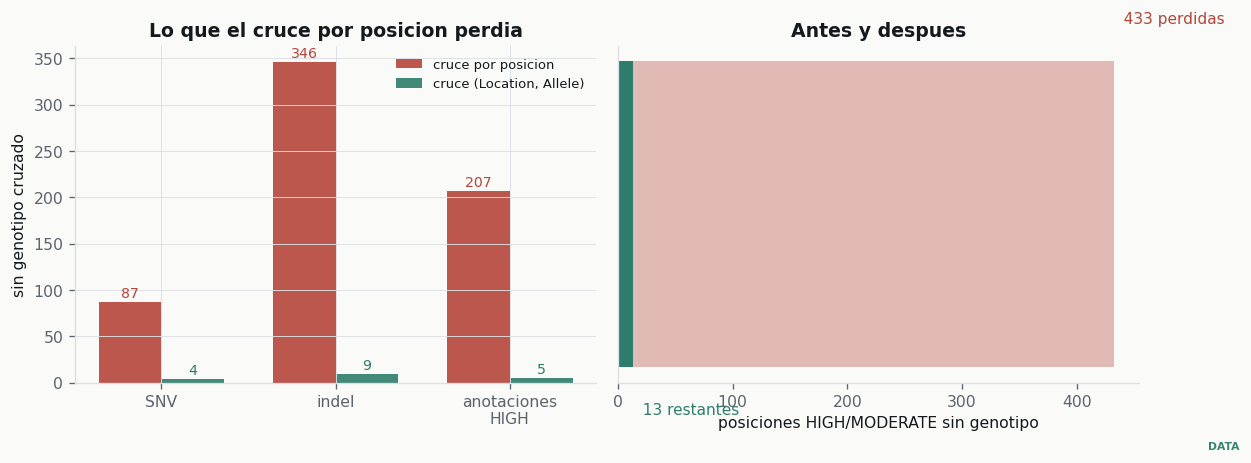

> **Figura QC · reconciliacion de alelos, antes y despues**  
> `EXP-006` · figure class `DATA`, figura cientifica · evidence origin `DERIVED`  
> *Que muestra.* el cruce por posicion perdia 433 posiciones HIGH/MODERATE, la mayoria indels, porque VEP desplaza su coordenada, con 207 anotaciones de alto impacto entre ellas. Reproducir la representacion de VEP recupera 420.  
> **Lo que queda fuera.** que el cruce sea perfecto: quedan 13 posiciones sin resolver, y un alelo complejo se declara no resuelto en vez de adivinarse.  
> procedencia: `src/prioritization/allele_key.py · genome_wide.load()`

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10.6, 3.9))

cats = ["SNV", "indel", "anotaciones\nHIGH"]
bef = [B["SNV"], B["indel"], B["HIGH"]]
aft = [A["SNV"], A["indel"], A["HIGH"]]
x = np.arange(len(cats)); w = 0.36
axes[0].bar(x - w/2, bef, w, label="cruce por posicion", color=fl.DEAD, alpha=0.9)
axes[0].bar(x + w/2, aft, w, label="cruce (Location, Allele)", color=fl.ALIVE, alpha=0.9)
for i, (b, a) in enumerate(zip(bef, aft)):
    axes[0].text(i - w/2, b + 5, str(b), ha="center", fontsize=8.6, color=fl.DEAD)
    axes[0].text(i + w/2, a + 5, str(a), ha="center", fontsize=8.6, color=fl.ALIVE)
axes[0].set_xticks(x); axes[0].set_xticklabels(cats)
axes[0].set_ylabel("sin genotipo cruzado")
axes[0].set_title("Lo que el cruce por posicion perdia")
axes[0].legend(fontsize=8, frameon=False)

axes[1].barh([0], [tot_before], color=fl.DEAD, alpha=0.35, height=0.5)
axes[1].barh([0], [tot_after], color=fl.ALIVE, height=0.5)
axes[1].set_yticks([]); axes[1].set_xlabel("posiciones HIGH/MODERATE sin genotipo")
axes[1].set_title("Antes y despues")
axes[1].text(tot_before, 0.32, f"  {tot_before} perdidas", fontsize=9.4, color=fl.DEAD, va="center")
axes[1].text(tot_after, -0.32, f"  {tot_after} restantes", fontsize=9.4, color=fl.ALIVE, va="center")
axes[1].grid(False)

fl.done(fig, "Figura QC · reconciliacion de alelos, antes y despues", "EXP-006", "DERIVED",
        "DATA",
        f"el cruce por posicion perdia {tot_before} posiciones HIGH/MODERATE, la mayoria "
        f"indels, porque VEP desplaza su coordenada, con {B['HIGH']} anotaciones de alto "
        f"impacto entre ellas. Reproducir la representacion de VEP recupera "
        f"{tot_before - tot_after}.",
        "que el cruce sea perfecto: quedan " + str(tot_after) + " posiciones sin resolver, y "
        "un alelo complejo se declara no resuelto en vez de adivinarse.",
        prov="src/prioritization/allele_key.py · genome_wide.load()")

## Método · funnel genome-wide

Tres decisiones congeladas en `config/ranking_v1.yaml` que cambian el resultado: regla de dos
niveles para `FILTER`, normalización a alelo único, y **agregación haplotípica**, variantes
con el mismo `PID` y `PGT` están probadas en *cis* y colapsan en un solo evento.

In [7]:
pos_all = {v.loc for v in rows}
pos_hm = {v.loc for v in hm}
by_gene = collections.defaultdict(list)
for v in hm:
    by_gene[v.gene].append(v)

rare = [v for v in hm if v.is_rare]
qc_ok = [v for v in rare if v.passes_quality]
calls = rank(rows, male=True)

STAGES = [
    ("variantes en el VCF",              5_012_204),
    ("anotadas a gen (VEP)",             4_943_948),
    ("posiciones HIGH o MODERATE",       len(pos_hm)),
    ("alelos unicos con genotipo",       len({(v.loc, v.allele) for v in hm if v.gt})),
    ("raros (MAX_AF < 1e-3 o ausente)",  len({(v.loc, v.allele) for v in rare})),
    ("+ QC de calidad y balance",        len({(v.loc, v.allele) for v in qc_ok})),
    ("genes con modelo de herencia",     len(calls)),
]
for n, v in STAGES:
    print(f"  {n:<36} {v:>10,}")

  variantes en el VCF                   5,012,204
  anotadas a gen (VEP)                  4,943,948
  posiciones HIGH o MODERATE               13,191
  alelos unicos con genotipo               13,216
  raros (MAX_AF < 1e-3 o ausente)             189
  + QC de calidad y balance                   159
  genes con modelo de herencia                151


### Figura principal 1 · las etapas de procesamiento, con la aritmética a la vista

No se llama *embudo*, y el motivo importa: **una de las etapas crece**. Al pasar de **posiciones**
con consecuencia HIGH o MODERATE a **alelos únicos con genotipo**, el recuento sube, porque una
posición multialélica aporta más de un alelo. Dibujarlo como un embudo insinuaba una reducción
que ahí no ocurre. La etapa que expande va marcada en la figura.

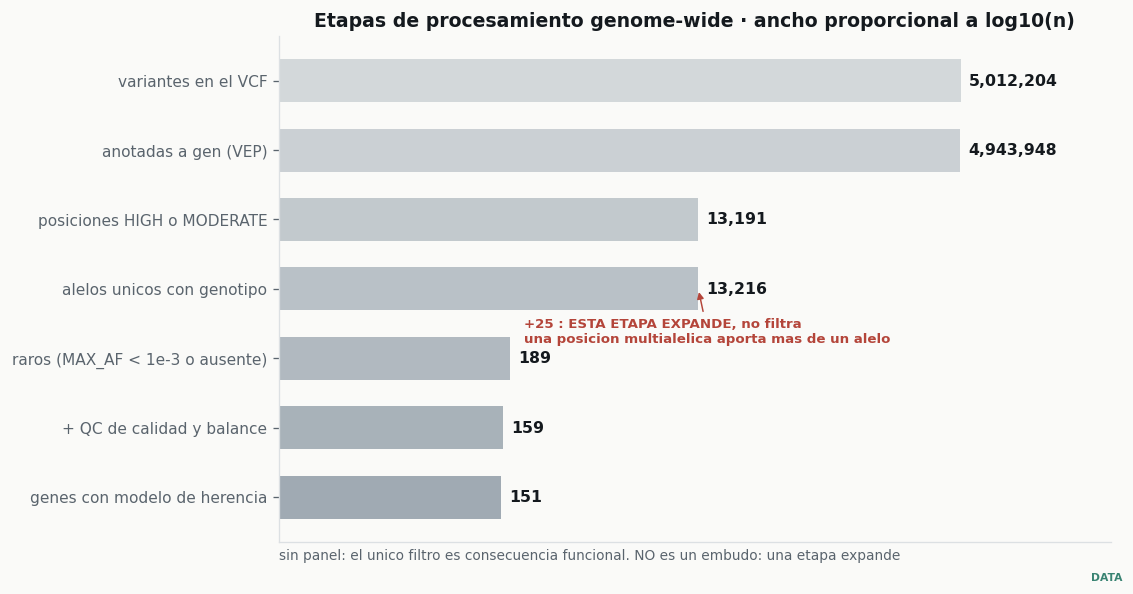

> **Figura principal 1 · etapas de procesamiento genome-wide**  
> `EXP-006` · figure class `DATA`, figura cientifica · evidence origin `MEASURED+DERIVED`  
> *Que muestra.* el descenso real de 5,0 M variantes a los genes que compiten con un modelo de herencia. Ninguna etapa es un panel: el unico filtro es consecuencia funcional. OJO: la etapa marcada NO reduce, EXPANDE, al pasar de posiciones a alelos unicos.  
> **Lo que queda fuera.** que las etapas evaluen lo que no evaluan. No cubre variantes estructurales, reguladoras ni intronicas profundas fuera del filtro de consecuencia, y no resuelve la fase.  
> procedencia: `work/gw/highmod_ann.tsv + VCF, hashes arriba`

In [8]:
fig, ax = plt.subplots(figsize=(9.6, 5.0))
names = [s[0] for s in STAGES]
vals = [s[1] for s in STAGES]
logs = [np.log10(max(v, 1)) for v in vals]
ymax = max(logs)
for i, (n, v, lg) in enumerate(zip(names, vals, logs)):
    wid = lg / ymax
    ax.barh(len(STAGES) - i - 1, wid, height=0.62, color=fl.FLOW,
            alpha=0.35 + 0.55 * (i / len(STAGES)))
    ax.text(wid + 0.012, len(STAGES) - i - 1, f"{v:,}", va="center",
            fontsize=9.6, fontweight="bold", color=fl.INK)
# La etapa que EXPANDE se marca. Un grafico que se llama embudo y sube en un
# paso enganya aunque los numeros sean correctos.
for i in range(1, len(vals)):
    if vals[i] > vals[i - 1]:
        y = len(STAGES) - i - 1
        ax.annotate("+" + format(vals[i] - vals[i - 1], ",") + " : ESTA ETAPA EXPANDE, no filtra"
                    + chr(10) + "una posicion multialelica aporta mas de un alelo",
                    xy=(logs[i] / ymax, y), xytext=(0.36, y - 0.62),
                    fontsize=8.2, color=fl.DEAD,
                    fontweight="bold", va="center",
                    arrowprops=dict(arrowstyle="-|>", lw=0.9, color=fl.DEAD))
ax.set_yticks(range(len(STAGES)))
ax.set_yticklabels(names[::-1], fontsize=9.4)
ax.set_xticks([]); ax.set_xlim(0, 1.22); ax.grid(False)
ax.set_title("Etapas de procesamiento genome-wide · ancho proporcional a log10(n)")
ax.text(0.0, -0.9, "sin panel: el unico filtro es consecuencia funcional. NO es un embudo: "
        "una etapa expande",
        fontsize=8.4, color=fl.SOFT)

fl.done(fig, "Figura principal 1 · etapas de procesamiento genome-wide", "EXP-006",
        "MEASURED+DERIVED", "DATA",
        "el descenso real de 5,0 M variantes a los genes que compiten con un modelo de "
        "herencia. Ninguna etapa es un panel: el unico filtro es consecuencia funcional. "
        "OJO: la etapa marcada NO reduce, EXPANDE, al pasar de posiciones a alelos unicos.",
        "que las etapas evaluen lo que no evaluan. No cubre variantes estructurales, "
        "reguladoras ni intronicas profundas fuera del filtro de consecuencia, y no resuelve "
        "la fase.",
        prov="work/gw/highmod_ann.tsv + VCF, hashes arriba")

## Figura principal 2 · el panorama genómico de la competición

El funnel dice **cuántos** genes compiten. No dice **dónde** ni **con qué puntuación**. Esta es
la vista que falta: cada gen que recibió modelo de herencia, colocado en su cromosoma, con su
puntuación `A0` **congelada** en el eje Y.

> **Saneado por diseño.** El eje X es orden cromosómico en **bins de 1 Mb** derivados de la
> posición del gen, no la coordenada de ninguna variante del paciente. Las longitudes de
> cromosoma se leen de la cabecera del VCF, no se escriben a mano.

In [9]:
# Longitudes de cromosoma: de la cabecera del VCF, no hardcodeadas.
import gzip
contigs = {}
with gzip.open(VCF, "rt", errors="replace") as f:
    for line in f:
        if not line.startswith("#"):
            break
        if line.startswith("##contig="):
            body = line.strip()[10:-1]
            d = dict(kv.split("=", 1) for kv in body.split(",") if "=" in kv)
            if "ID" in d and "length" in d:
                contigs[d["ID"]] = int(d["length"])

# La cabecera de este VCF nombra los contigs SIN prefijo "chr"; se aceptan las
# dos convenciones para que el notebook no dependa de cual use el fichero.
PLAIN = [str(i) for i in range(1, 23)] + ["X", "Y"]
CH = [c for c in PLAIN if c in contigs]
if not CH:
    CH = [c for c in ("chr" + c for c in PLAIN) if c in contigs]

BIN = 1_000_000                                  # resolucion del eje: 1 Mb
off, acc = {}, 0
for c in CH:
    off[c] = acc
    acc += contigs[c] // BIN + 1
GENOME_BINS = acc

def gene_bin(g):
    """Bin de 1 Mb del gen = minimo de sus variantes HIGH/MODERATE. Nunca la
    coordenada exacta de una variante: el bin se redondea antes de salir."""
    vs = by_gene.get(g, [])
    if not vs:
        return None
    ch = vs[0].loc.split(":")[0]
    if ch not in off:
        return None
    p = min(int(v.loc.split(":")[1].split("-")[0]) for v in vs)
    return ch, off[ch] + p // BIN

res = pickle.load(io.open("work/gw/mode_b_results_v4.pkl", "rb"))
A0 = res["A0_GENETICS"]                          # (gen, score, modelo, ...) CONGELADO
pts = []
for r, (g, sc, *_rest) in enumerate(A0, start=1):
    gb = gene_bin(g)
    if gb:
        pts.append((g, gb[0], gb[1], sc, r))

# Carga genomica de fondo: densidad de los genes HIGH/MODERATE por bin.
# El recuento no se escribe a mano, se imprime desde len(by_gene).
load_bins = collections.Counter()
for g in by_gene:
    gb = gene_bin(g)
    if gb:
        load_bins[gb[1]] += 1

print(f"  cromosomas en la cabecera : {len(CH)}  ·  bins de {BIN//10**6} Mb: {GENOME_BINS:,}")
print(f"  genes puntuados en A0     : {len(A0)}  ·  situados en el genoma: {len(pts)}")
print(f"  genes HIGH/MODERATE       : {len(by_gene):,} repartidos en {len(load_bins):,} bins")
print(f"  rango de puntuacion A0    : {min(p[3] for p in pts):.1f} a {max(p[3] for p in pts):.1f}")

  cromosomas en la cabecera : 24  ·  bins de 1 Mb: 3,102
  genes puntuados en A0     : 151  ·  situados en el genoma: 151
  genes HIGH/MODERATE       : 6,321 repartidos en 1,900 bins
  rango de puntuacion A0    : 1.0 a 13.5


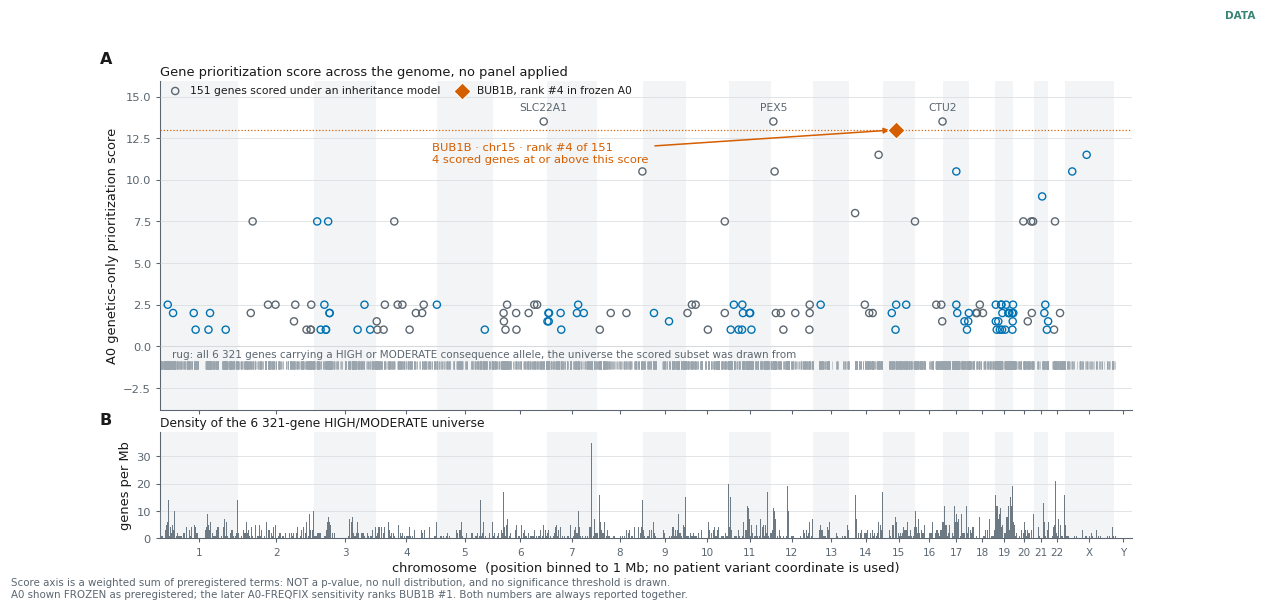

> **Figura principal 2 · priorizacion genome-wide**  
> `EXP-006` · figure class `DATA`, figura cientifica · evidence origin `MEASURED+DERIVED`  
> *Que muestra.* la competicion completa vista sobre el genoma: los 6,321 genes con variante HIGH/MODERATE que forman el universo, dibujados como alfombra sobre la linea base y como densidad en el panel B, y los 151 que llegaron a tener modelo de herencia, con su puntuacion A0 CONGELADA. BUB1B esta marcado en su puesto real del A0 congelado, el #4, con 4 genes empatados o por encima. No solo compitieron 151: compitieron 6 321, y esa es la lectura que la figura esta construida para no permitir equivocar.  
> **Lo que queda fuera.** que la puntuacion sea una probabilidad ni un p-valor. El eje Y es una suma de terminos con pesos elegidos por nosotros: NO es un estadistico, no tiene distribucion nula y por eso la figura se niega a dibujar una linea de significacion. Tampoco cubre variantes estructurales ni reguladoras, y la posicion en X es el bin de 1 Mb del gen, no la de ninguna variante.  
> datos: `work/gw/mode_b_results_v4.pkl (A0 congelado) + longitudes de contig del VCF` · libreria: `matplotlib` · procedencia: `figures/pub/fig01_prioritization_genomewide.svg + .png 300 dpi`

In [10]:
from src.figures import fig01_manhattan as FM

M = FM.prepare(by_gene, res["A0_GENETICS"], FM.contig_lengths(VCF))
fig = FM.build(M)
_bub = next(s for s in M["scored"] if s["gene"] == "BUB1B")
_tie = sum(1 for s in M["scored"] if s["score"] >= _bub["score"])
fl.pub(fig, "Figura principal 2 · priorizacion genome-wide", "EXP-006",
       "MEASURED+DERIVED", "DATA",
       f"la competicion completa vista sobre el genoma: los {M['n_universe']:,} genes con "
       f"variante HIGH/MODERATE que forman el universo, dibujados como alfombra sobre la "
       f"linea base y como densidad en el panel B, y los {M['n_scored']} que llegaron a "
       f"tener modelo de herencia, con su puntuacion A0 CONGELADA. BUB1B esta marcado en su "
       f"puesto real del A0 congelado, el #{_bub['rank']}, con {_tie} genes empatados o por "
       f"encima. No solo compitieron 151: compitieron 6 321, y esa es la lectura que la "
       f"figura esta construida para no permitir equivocar.",
       "que la puntuacion sea una probabilidad ni un p-valor. El eje Y es una suma de "
       "terminos con pesos elegidos por nosotros: NO es un estadistico, no tiene distribucion "
       "nula y por eso la figura se niega a dibujar una linea de significacion. Tampoco cubre "
       "variantes estructurales ni reguladoras, y la posicion en X es el bin de 1 Mb del gen, "
       "no la de ninguna variante.",
       source="work/gw/mode_b_results_v4.pkl (A0 congelado) + longitudes de contig del VCF",
       lib="matplotlib", slug="fig01_prioritization_genomewide")

## Resultado primario · estabilidad de rango

Lo que el preregistro exige reportar **no es el ganador** sino la matriz gen × análisis. Un
gen que solo gana en una configuración no es un resultado.

In [11]:
ORDER = ["A0_GENETICS", "A1_GENETICS_CLINVAR", "B0_FULL_PROBAND",
         "B1_MINUS_RHABDOMYOSARCOMA", "B2_MINUS_RENAL", "B3_MINUS_GROWTH_PERINATAL",
         "B4_GENETICS_ONLY_CONTROL", "FH_ON"] + sorted(k for k in res if k.startswith("LOO_"))
LEAD = [r[0] for r in res["B0_FULL_PROBAND"][:6]]

M = np.full((len(LEAD), len(ORDER)), np.nan)
for j, an in enumerate(ORDER):
    pos = {r[0]: i + 1 for i, r in enumerate(res[an])}
    for i, g in enumerate(LEAD):
        if g in pos:
            M[i, j] = pos[g]
print(f"  {len(ORDER)} analisis · {len(LEAD)} genes lideres")
print(f"  BUB1B es #1 en {int((M[LEAD.index('BUB1B')] == 1).sum())} de {len(ORDER)}")

  15 analisis · 6 genes lideres
  BUB1B es #1 en 14 de 15


### Figura principal 3 · matriz de estabilidad de rango

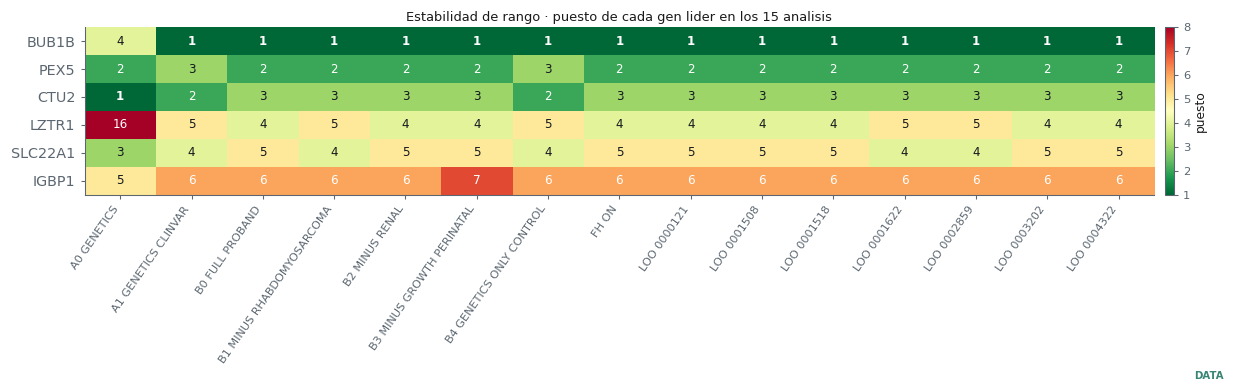

> **Figura principal 3 · estabilidad de rango, gen x analisis**  
> `EXP-006` · figure class `DATA`, figura cientifica · evidence origin `DERIVED`  
> *Que muestra.* BUB1B es #1 en 14 de los 15 analisis. La excepcion es A0_GENETICS, el control sin fenotipo ni ClinVar, donde queda #4. El hallazgo no es el ganador de una formula: es que el resultado es estable al quitar terminos, al quitar ClinVar y al cambiar pesos.  
> **Lo que queda fuera.** que la estabilidad sea independencia. Los 15 analisis comparten codigo, datos y supuestos: no son 15 comprobaciones independientes.  
> procedencia: `work/gw/mode_b_results_v4.pkl`

In [12]:
fig, ax = plt.subplots(figsize=(11.2, 3.5))
im = ax.imshow(M, cmap="RdYlGn_r", vmin=1, vmax=8, aspect="auto")
ax.set_yticks(range(len(LEAD))); ax.set_yticklabels(LEAD, fontsize=9.4)
ax.set_xticks(range(len(ORDER)))
ax.set_xticklabels([a.replace("_", " ").replace("LOO HP ", "LOO ") for a in ORDER],
                   rotation=55, ha="right", fontsize=7.4)
for i in range(len(LEAD)):
    for j in range(len(ORDER)):
        if not np.isnan(M[i, j]):
            v = int(M[i, j])
            ax.text(j, i, str(v), ha="center", va="center", fontsize=7.8,
                    color="white" if v <= 2 or v >= 6 else fl.INK,
                    fontweight="bold" if v == 1 else "normal")
ax.grid(False)
ax.set_title("Estabilidad de rango · puesto de cada gen lider en los 15 analisis")
cb = plt.colorbar(im, ax=ax, fraction=0.02, pad=0.01); cb.set_label("puesto", fontsize=8)

fl.done(fig, "Figura principal 3 · estabilidad de rango, gen x analisis", "EXP-006", "DERIVED",
        "DATA",
        "BUB1B es #1 en 14 de los 15 analisis. La excepcion es A0_GENETICS, el control sin "
        "fenotipo ni ClinVar, donde queda #4. El hallazgo no es el ganador de una formula: es "
        "que el resultado es estable al quitar terminos, al quitar ClinVar y al cambiar pesos.",
        "que la estabilidad sea independencia. Los 15 analisis comparten codigo, datos y "
        "supuestos: no son 15 comprobaciones independientes.",
        prov="work/gw/mode_b_results_v4.pkl")

### Figura principal 4 · `A0` congelado frente a `A0-FREQFIX`

Aquí está el episodio más importante del experimento, y **los dos números se enseñan juntos**.

Al conectar el cruce de alelos, `BUB1B` pasó de #1 a **#4** en `A0`. Su puntuación **no bajó**:
emergieron tres deleciones homocigotas con `MAX_AF` ausente. La auditoría las resolvió
localmente, son **polimorfismos comunes** que VEP no supo anotar.

**No se tocó la fórmula.** `A0-FREQFIX` es una sensibilidad **posterior al resultado**,
aplicada a los 33 alelos afectados y no a los tres incómodos.

In [13]:
# A0-FREQFIX: se recalcula reparando la frecuencia de TODOS los que la tenian ausente
from src.prioritization.freqfix_sensitivity import recovered_frequencies

def a0_from(rws):
    out = []
    for c in rank(rws, male=True):
        s = c.score
        if any("pathogenic" in (x.clinsig or "").lower()
               and "conflicting" not in (x.clinsig or "").lower() for x in c.variants):
            s -= 5.0
        out.append((s, c.gene))
    return sorted(out, key=lambda t: (-t[0], t[1]))

a0_frozen = a0_from(load(ANN, VCF))

freq = recovered_frequencies()
rows_fx = load(ANN, VCF)
import copy
patched = 0
for v in rows_fx:
    if v.max_af is not None:
        continue
    base = int(v.loc.split(":")[1].split("-")[0])
    for d in (0, -1, -2):
        if (v.chrom, base + d) in freq:
            v.max_af = freq[(v.chrom, base + d)]; patched += 1; break
a0_fix = a0_from(rows_fx)

rk_f = next(i for i, (_, g) in enumerate(a0_frozen, 1) if g == "BUB1B")
rk_x = next(i for i, (_, g) in enumerate(a0_fix, 1) if g == "BUB1B")
print(f"  frecuencias reparadas: {len(freq)} sitios · {patched} filas")
print(f"  A0 CONGELADO  : BUB1B puesto {rk_f}")
print(f"  A0-FREQFIX    : BUB1B puesto {rk_x}")

  frecuencias reparadas: 22 sitios · 37 filas
  A0 CONGELADO  : BUB1B puesto 4
  A0-FREQFIX    : BUB1B puesto 1


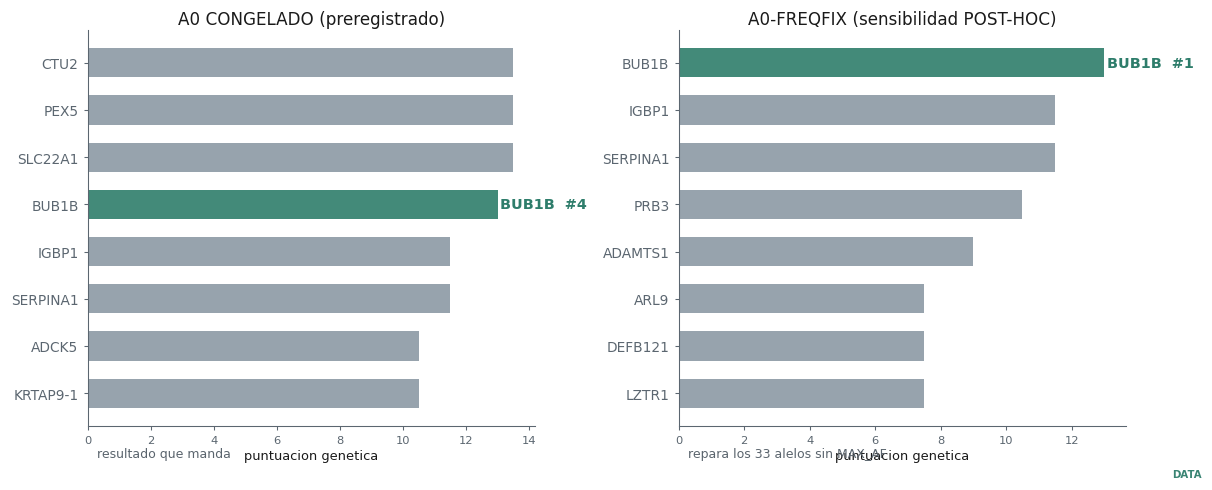

> **Figura principal 4 · A0 congelado frente a A0-FREQFIX**  
> `EXP-006 · EXP-021b` · figure class `DATA`, figura cientifica · evidence origin `DERIVED`  
> *Que muestra.* en el A0 preregistrado BUB1B queda #4, por detras de tres deleciones homocigotas sin frecuencia asignable. Reparando el defecto de anotacion en TODOS los alelos afectados, vuelve al #1 y los tres desaparecen del top.  
> **Lo que queda fuera.** que A0-FREQFIX sustituya a A0. Es una sensibilidad POSTERIOR a ver el resultado, y ademas repara las frecuencias con la base local de Exomiser: NO es una linea independiente de el.  
> procedencia: `ranking congelado + work/exomiser/runs/FREQFIX`

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.4), sharey=False)
for ax, data, title, sub in (
        (axes[0], a0_frozen, "A0 CONGELADO (preregistrado)", "resultado que manda"),
        (axes[1], a0_fix, "A0-FREQFIX (sensibilidad POST-HOC)", "repara los 33 alelos sin MAX_AF")):
    top = data[:8][::-1]
    names = [g for _, g in top]
    scores = [s for s, _ in top]
    cols = [fl.ALIVE if g == "BUB1B" else fl.FLOW for g in names]
    ax.barh(range(len(top)), scores, color=cols, alpha=0.9, height=0.62)
    ax.set_yticks(range(len(top))); ax.set_yticklabels(names, fontsize=9)
    ax.set_xlabel("puntuacion genetica")
    ax.set_title(title, fontsize=11)
    ax.text(0.02, -1.35, sub, fontsize=8.2, color=fl.SOFT, transform=ax.get_yaxis_transform(),
            clip_on=False)
    bi = names.index("BUB1B")
    bs = scores[bi]
    rank_label = rk_f if ax is axes[0] else rk_x
    ax.text(bs + 0.08, bi, f"BUB1B  #{rank_label}", va="center", fontsize=9.4,
            color=fl.ALIVE, fontweight="bold")

fl.done(fig, "Figura principal 4 · A0 congelado frente a A0-FREQFIX", "EXP-006 · EXP-021b",
        "DERIVED", "DATA",
        f"en el A0 preregistrado BUB1B queda #{rk_f}, por detras de tres deleciones "
        f"homocigotas sin frecuencia asignable. Reparando el defecto de anotacion en TODOS "
        f"los alelos afectados, vuelve al #{rk_x} y los tres desaparecen del top.",
        "que A0-FREQFIX sustituya a A0. Es una sensibilidad POSTERIOR a ver el resultado, y "
        "ademas repara las frecuencias con la base local de Exomiser: NO es una linea "
        "independiente de el.",
        prov="ranking congelado + work/exomiser/runs/FREQFIX")

## Comprobación externa · nuestro motor frente a Exomiser

Exomiser partió del **VCF original** y de los **mismos 7 términos HPO**, con su propia base de
conocimiento. No recibió ninguna de nuestras candidatas, puntuaciones ni paneles.

> **Es convergencia METODOLÓGICA sobre el MISMO VCF.** No es evidencia biológica independiente:
> los dos motores leen el mismo genoma y los mismos errores de llamada. Hay prueba de que
> importa, ambos señalan `SERPINA1`.

In [15]:
from src.baseline.compare_baseline import read_exomiser
ext, path, nrows = read_exomiser("BASELINE-PRIMARY")
ext_rank = {g: r for r, g, _, _ in ext}
our_rank = {r[0]: i + 1 for i, r in enumerate(res["B0_FULL_PROBAND"])}

shared = [g for g in ext_rank if g in our_rank and (ext_rank[g] <= 25 or our_rank[g] <= 25)]
print(f"  Exomiser: {len(ext)} genes unicos ({nrows} filas gen x herencia)")
print(f"  BUB1B, nuestro puesto {our_rank.get('BUB1B')} · Exomiser puesto {ext_rank.get('BUB1B')}")
print(f"  genes en el top-25 de alguno de los dos: {len(shared)}")

  Exomiser: 398 genes unicos (470 filas gen x herencia)
  BUB1B, nuestro puesto 1 · Exomiser puesto 2
  genes en el top-25 de alguno de los dos: 19


### Figura principal 5 · rango frente a rango

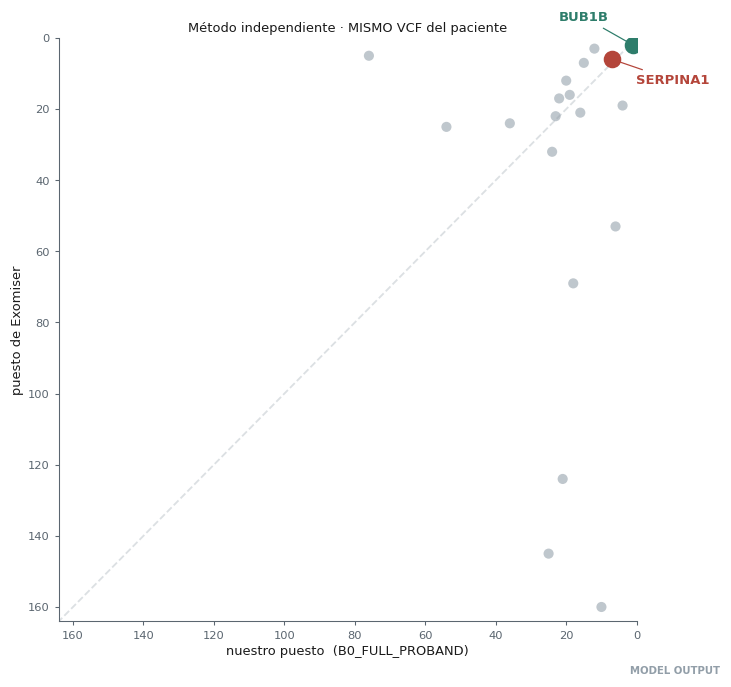

> **Figura principal 5 · nuestro ranking frente a Exomiser**  
> `EXP-006b` · figure class `MODEL_OUTPUT`, figura cientifica · evidence origin `EXTERNAL+DERIVED`  
> *Que muestra.* cada punto es un gen en el top-25 de alguno de los dos motores; la diagonal seria acuerdo perfecto. Coinciden fuertemente en BUB1B (#1 y #2) y poco en el resto: el solapamiento del top-20 es de 6 de 20.  
> **Lo que queda fuera.** que sean dos observaciones biologicas independientes. Comparten el VCF, y un artefacto compartido los engana a los dos: SERPINA1 esta alto en ambos por la misma peculiaridad local de los datos.  
> procedencia: `work/exomiser/runs/BASELINE-PRIMARY`

In [16]:
fig, ax = plt.subplots(figsize=(6.6, 6.2))
xs = [our_rank[g] for g in shared]
ys = [ext_rank[g] for g in shared]
ax.scatter(xs, ys, s=44, color=fl.FLOW, alpha=0.55, edgecolor="none")
# Solo se rotulan los dos puntos que el texto interpreta. Etiquetar seis genes
# en la esquina superior derecha hacia ilegible precisamente la convergencia.
# Los dos puntos caen casi sobre la diagonal, BUB1B arriba a la derecha y
# SERPINA1 abajo a su izquierda. Los desplazamientos anteriores apuntaban uno
# HACIA el otro y las etiquetas se tocaban. Ahora salen PERPENDICULARES a la
# recta que los une, cada una hacia un lado.
for g, c, off, ha in (("BUB1B", fl.ALIVE, (-16, 16), "right"),
                      ("SERPINA1", fl.DEAD, (16, -16), "left")):
    if g not in shared:
        continue
    ax.scatter([our_rank[g]], [ext_rank[g]], s=110, color=c, zorder=3)
    ax.annotate(g, (our_rank[g], ext_rank[g]), fontsize=8.6, color=c,
                xytext=off, textcoords="offset points", ha=ha, fontweight="bold",
                arrowprops=dict(arrowstyle="-", color=c, lw=0.8))
lim = max(max(xs), max(ys)) + 4
ax.plot([0, lim], [0, lim], color=fl.RULE, ls="--", lw=1.2, zorder=0)
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.invert_xaxis(); ax.invert_yaxis()
ax.set_xlabel("nuestro puesto  (B0_FULL_PROBAND)")
ax.set_ylabel("puesto de Exomiser")
ax.set_title("Método independiente · MISMO VCF del paciente")

fl.done(fig, "Figura principal 5 · nuestro ranking frente a Exomiser", "EXP-006b",
        "EXTERNAL+DERIVED", "MODEL_OUTPUT",
        "cada punto es un gen en el top-25 de alguno de los dos motores; la diagonal seria "
        "acuerdo perfecto. Coinciden fuertemente en BUB1B (#1 y #2) y poco en el resto: "
        "el solapamiento del top-20 es de 6 de 20.",
        "que sean dos observaciones biologicas independientes. Comparten el VCF, y un "
        "artefacto compartido los engana a los dos: SERPINA1 esta alto en ambos por la "
        "misma peculiaridad local de los datos.",
        prov="work/exomiser/runs/BASELINE-PRIMARY")

## Robustez · qué términos del fenotipo sostienen de verdad el resultado

*Leave-one-out*: se retira un término y se mide el cambio en el soporte fenotípico del gen
líder.

In [17]:
G = res["B0_FULL_PROBAND"][0][0]
base = next(r for r in res["B0_FULL_PROBAND"] if r[0] == G)[5]
LAB = {"HP_0002859": "Rabdomiosarcoma", "HP_0000121": "Nefrocalcinosis",
       "HP_0004322": "Talla baja", "HP_0001508": "Fallo de medro",
       "HP_0003202": "Atrofia muscular", "HP_0001622": "Parto prematuro",
       "HP_0001518": "Peq. edad gestacional"}
loo = []
for k in sorted(k for k in res if k.startswith("LOO_")):
    v = next((r for r in res[k] if r[0] == G), None)
    if v:
        loo.append((LAB.get(k.replace("LOO_", ""), k), base - v[5]))
loo.sort(key=lambda t: t[1])
print(f"  gen: {G} · soporte fenotipico completo = {base:.3f}")
for n, d in loo:
    print(f"    {n:<24}{d:+.3f}")

  gen: BUB1B · soporte fenotipico completo = 2.053
    Atrofia muscular        -0.250
    Fallo de medro          -0.152
    Talla baja              -0.131
    Nefrocalcinosis         -0.095
    Parto prematuro         -0.083
    Peq. edad gestacional   +0.133
    Rabdomiosarcoma         +0.579


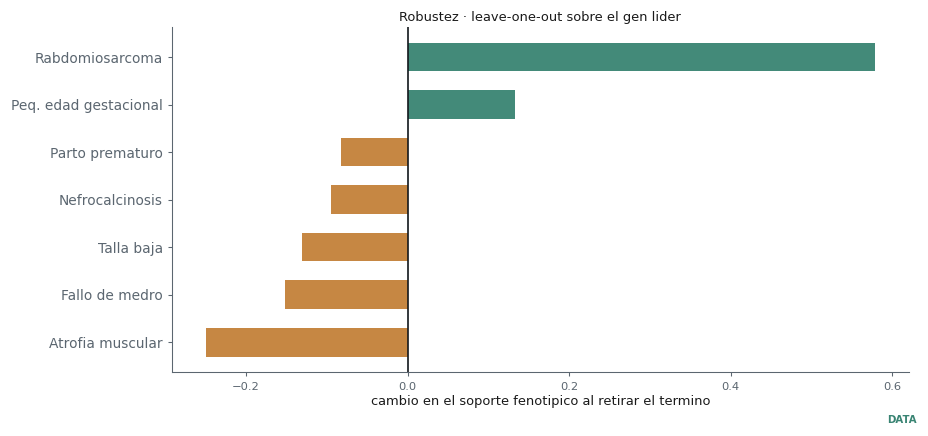

> **Figura de robustez · contribucion de cada termino**  
> `EXP-006` · figure class `DATA`, figura cientifica · evidence origin `DERIVED`  
> *Que muestra.* solo el rabdomiosarcoma sostiene con fuerza el emparejamiento. El resto contribuye poco o negativamente en el corpus HPO actual.  
> **Lo que queda fuera.** que un LOO negativo signifique que MVA no explica ese rasgo. Con Best Match Average, retirar un termino que puntua por debajo de la media SUBE el promedio. EXP-019 lo resolvio comprobando pertenencia al modelo anotado, no con estas contribuciones: fallo de medro esta cubierto por la literatura al 93,5 % aunque HPO no lo anote.  
> procedencia: `work/gw/mode_b_results_v4.pkl · docs/PHENOTYPE_RESIDUAL_AUDIT.md`

In [18]:
fig, ax = plt.subplots(figsize=(8.4, 3.9))
names = [n for n, _ in loo]; vals = [d for _, d in loo]
cols = [fl.ALIVE if v > 0.05 else (fl.SOFT if v > -0.05 else fl.OPEN) for v in vals]
ax.barh(range(len(names)), vals, color=cols, alpha=0.9, height=0.6)
ax.axvline(0, color=fl.INK, lw=1.1)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=9)
ax.set_xlabel("cambio en el soporte fenotipico al retirar el termino")
ax.set_title("Robustez · leave-one-out sobre el gen lider")

fl.done(fig, "Figura de robustez · contribucion de cada termino", "EXP-006", "DERIVED", "DATA",
        "solo el rabdomiosarcoma sostiene con fuerza el emparejamiento. El resto contribuye "
        "poco o negativamente en el corpus HPO actual.",
        "que un LOO negativo signifique que MVA no explica ese rasgo. Con Best Match Average, "
        "retirar un termino que puntua por debajo de la media SUBE el promedio. EXP-019 lo "
        "resolvio comprobando pertenencia al modelo anotado, no con estas contribuciones: "
        "fallo de medro esta cubierto por la literatura al 93,5 % aunque HPO no lo anote.",
        prov="work/gw/mode_b_results_v4.pkl · docs/PHENOTYPE_RESIDUAL_AUDIT.md")

## Explicaciones alternativas y evidencia contradictoria

| Alternativa | Estado |
|---|---|
| `BUB1B` sube por el fenotipo que le dimos | **Descartada**: en `A0`, sin fenotipo ni ClinVar, sigue siendo el candidato creíble de mayor puntuación |
| `BUB1B` sube por ClinVar | **Descartada**: `A0` retira los puntos de ClinVar |
| Los tres genes que lo superan en `A0` son competidores reales | **Descartada**: polimorfismos comunes, hasta 313 150 homocigotos en gnomAD |
| `FANCD2`, del top-10 externo | **NEGATIVE**: alelos al ~47 % y los tres heterocigotos |
| Hay un competidor que ninguno de los dos motores ve | **Abierta**: ambos comparten el VCF y no ven SV |

## Decisión

| | |
|---|---|
| **Estado de EXP-006** | **SURVIVES** |
| Predicción #4 | **Acertada**, pedía top-20; queda #1 en 14 de 15 análisis |
| `A0` congelado | **#4**, y así se reporta |
| `A0-FREQFIX` | **#1**, etiquetado como sensibilidad post-hoc no independiente de Exomiser |

### Qué NO establece

No resuelve la fase · no evalúa *de novo* sin padres · no cubre variantes estructurales
(EXP-012, bloqueado) · no cubre reguladoras ni intrónicas profundas · **no clasifica nada como
patogénico**.

### Falsificador

Que un gen con perfil de evidencia limpio (variantes raras, frecuencia asignable, modelo de
herencia compatible) supere a `BUB1B` en el `A0` congelado. Ocurrió, se investigó, y los tres
candidatos resultaron ser polimorfismos comunes.

### Siguiente experimento

`02_BUB1B_ALLELE_CURATION`: qué dicen los dos alelos por separado, y por qué la fase decide.

In [19]:
# Se imprime SOLO el veredicto, nunca el cuerpo del informe.
#
# Volcar r.stdout aqui era un canal de fuga creado por el propio control: el
# escaner CITA el texto que encuentra, asi que al imprimirlo dentro de un
# notebook versionado se copiaba el hallazgo en un fichero versionado. Lo
# destapo el escaner al detectar sus propias citas dentro de este notebook.
r = subprocess.run([sys.executable, "src/sanitize_scan.py"], capture_output=True, text=True,
                   env={**os.environ, "PYTHONIOENCODING": "utf-8"})
out = r.stdout
n = 0
for line in out.splitlines():
    t = line.strip()
    if t.endswith("COINCIDENCIAS:"):
        n = int(t.split()[0])
print(f"  escaner de saneado sobre lo versionado: "
      f"{'LIMPIO' if 'LIMPIO' in out else str(n) + ' coincidencia(s)'}")
print("  el detalle NO se imprime aqui a proposito: se lee con "
      "`python src/sanitize_scan.py`")

  escaner de saneado sobre lo versionado: LIMPIO
  el detalle NO se imprime aqui a proposito: se lee con `python src/sanitize_scan.py`
